# Acid-base equilibria: exact pH, speciation and titrations

`phcalc` solves the full charge balance; it does not rely on the usual textbook shortcuts. This notebook covers:

1. a table of common solutions, comparing the exact pH with the shortcut formulas,
2. speciation (alpha) diagrams for phosphoric and citric acid,
3. a log-concentration (Sillén) diagram for acetic acid,
4. titration curves: strong vs weak acid, and triprotic phosphoric acid,
5. buffer capacity of an acetate buffer, comparing the analytic and numerical values.

In [1]:
import sys, math
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import phcalc as ph

## 1. pH of common solutions

In [2]:
cases = {
    "0.01 M HCl": ph.Solution(anions=0.01),
    "1e-8 M HCl": ph.Solution(anions=1e-8),
    "0.1 M acetic acid": ph.Solution([ph.acid("acetic", 0.1)]),
    "0.1 M sodium acetate": ph.Solution([ph.acid("acetic", 0.1)], cations=0.1),
    "0.1 M ammonia": ph.Solution([ph.acid("ammonium", 0.1)]),
    "0.1 M NH4Cl": ph.Solution([ph.acid("ammonium", 0.1)], anions=0.1),
    "0.1 M NaH2PO4": ph.Solution([ph.acid("phosphoric", 0.1)], cations=0.1),
    "0.1 M Na2CO3": ph.Solution([ph.acid("carbonic", 0.1)], cations=0.2),
}
shortcut = {
    "0.01 M HCl": 2.0,
    "1e-8 M HCl": 8.0,  # the classic trap: ignoring water gives a basic answer
    "0.1 M acetic acid": 0.5 * (4.76 + 1),
    "0.1 M sodium acetate": 14 - 0.5 * (14 - 4.76 + 1),
    "0.1 M ammonia": 14 - 0.5 * (14 - 9.25 + 1),
    "0.1 M NH4Cl": 0.5 * (9.25 + 1),
    "0.1 M NaH2PO4": 0.5 * (2.15 + 7.20),
    "0.1 M Na2CO3": 14 - 0.5 * (14 - 10.33 + 1),
}
print(f"{'solution':<22}{'exact pH':>10}{'shortcut':>10}")
for name, sol in cases.items():
    print(f"{name:<22}{sol.pH():>10.3f}{shortcut[name]:>10.3f}")

solution                exact pH  shortcut
0.01 M HCl                 2.000     2.000
1e-8 M HCl                 6.978     8.000
0.1 M acetic acid          2.883     2.880
0.1 M sodium acetate       8.880     8.880
0.1 M ammonia             11.122    11.125
0.1 M NH4Cl                5.125     5.125
0.1 M NaH2PO4              4.690     4.675
0.1 M Na2CO3              11.655    11.665


## 2. Speciation diagrams

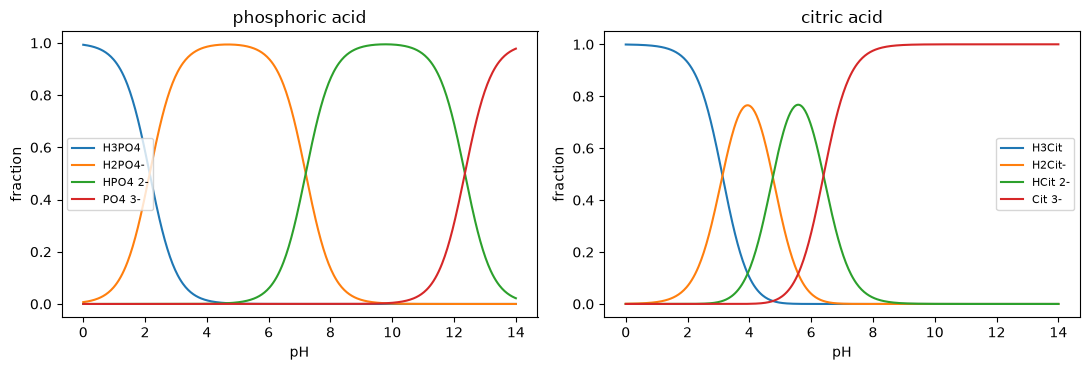

In [3]:
pH = np.linspace(0, 14, 500)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name, labels in [(axes[0], "phosphoric", ["H3PO4", "H2PO4-", "HPO4 2-", "PO4 3-"]),
                         (axes[1], "citric", ["H3Cit", "H2Cit-", "HCit 2-", "Cit 3-"])]:
    a = ph.alpha_fractions(ph.PKA[name][0], pH)
    for frac, lab in zip(a, labels):
        ax.plot(pH, frac, label=lab)
    ax.set_title(f"{name} acid"); ax.set_xlabel("pH"); ax.set_ylabel("fraction"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Log-concentration diagram, 0.1 M acetic acid

The pH of the pure acid sits where [H+] meets [A-] (the proton condition), marked by the dashed line.

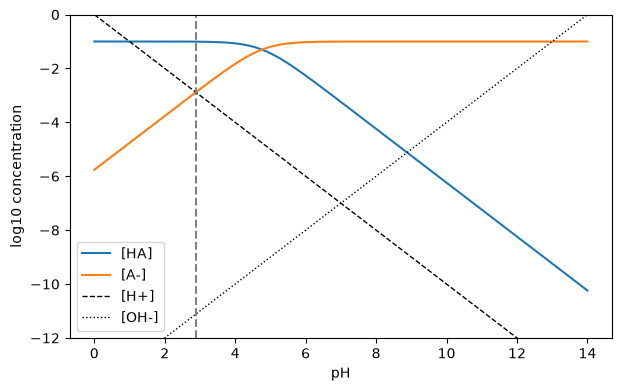

pH of 0.1 M acetic acid = 2.883


In [4]:
c = 0.1
a = ph.alpha_fractions(4.76, pH)
plt.figure(figsize=(7, 4.2))
plt.plot(pH, np.log10(c * a[0]), label="[HA]")
plt.plot(pH, np.log10(c * a[1]), label="[A-]")
plt.plot(pH, -pH, "k--", lw=1, label="[H+]")
plt.plot(pH, pH - 14, "k:", lw=1, label="[OH-]")
p0 = ph.Solution([ph.acid("acetic", c)]).pH()
plt.axvline(p0, c="gray", ls="--")
plt.ylim(-12, 0); plt.xlabel("pH"); plt.ylabel("log10 concentration"); plt.legend(); plt.show()
print(f"pH of 0.1 M acetic acid = {p0:.3f}")

## 4. Titration curves

0.1 M HCl -> equivalence at [25.0] mL


0.1 M acetic acid -> equivalence at [25.0] mL


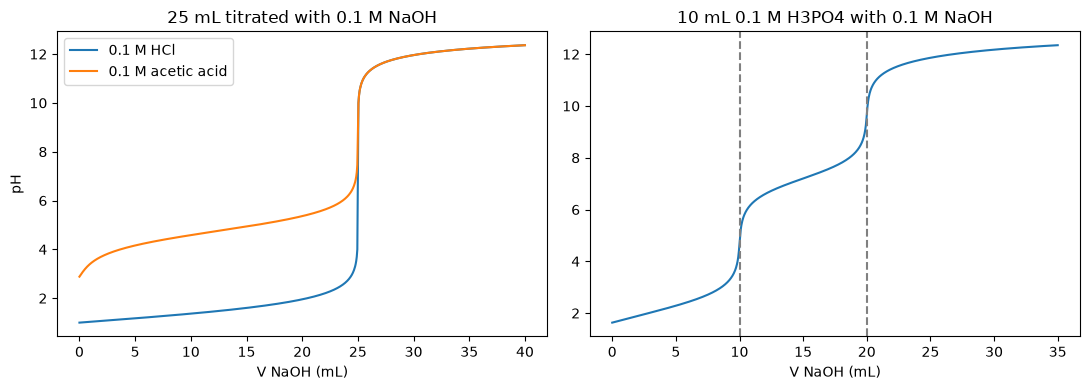

phosphoric acid equivalence points: [10.0, 20.0] mL (third proton too weak to show a break)


In [5]:
naoh = ph.Solution(cations=0.1)
v = np.linspace(0, 40, 801)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, analyte in [("0.1 M HCl", ph.Solution(anions=0.1)), ("0.1 M acetic acid", ph.Solution([ph.acid("acetic", 0.1)]))]:
    curve = ph.titration_curve(analyte, 25.0, naoh, v)
    axes[0].plot(v, curve, label=name)
    print(name, "-> equivalence at", [round(x, 2) for x in ph.equivalence_points(v, curve)], "mL")
axes[0].set_title("25 mL titrated with 0.1 M NaOH"); axes[0].set_xlabel("V NaOH (mL)"); axes[0].set_ylabel("pH"); axes[0].legend()

v3 = np.linspace(0, 35, 1401)
curve3 = ph.titration_curve(ph.Solution([ph.acid("phosphoric", 0.1)]), 10.0, naoh, v3)
eqs = ph.equivalence_points(v3, curve3)
axes[1].plot(v3, curve3)
for e in eqs:
    axes[1].axvline(e, ls="--", c="gray")
axes[1].set_title("10 mL 0.1 M H3PO4 with 0.1 M NaOH"); axes[1].set_xlabel("V NaOH (mL)")
plt.tight_layout(); plt.show()
print("phosphoric acid equivalence points:", [round(e, 2) for e in eqs], "mL (third proton too weak to show a break)")

## 5. Buffer capacity of 0.1 M acetate buffer

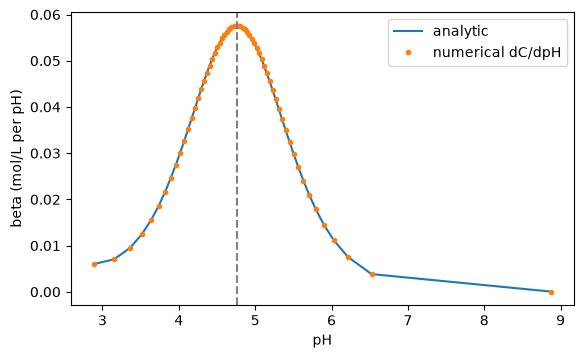

maximum beta = 0.0576 M at pH 4.75  (theory: 2.303 C/4 = 0.0576)


In [6]:
base = np.linspace(0.0, 0.1, 60)
pHs, beta_an, beta_num = [], [], []
for cb in base:
    sol = ph.Solution([ph.acid("acetic", 0.1)], cations=cb)
    p = sol.pH(); pHs.append(p); beta_an.append(sol.buffer_capacity())
    p2 = ph.Solution([ph.acid("acetic", 0.1)], cations=cb + 1e-6).pH()
    beta_num.append(1e-6 / (p2 - p))
plt.figure(figsize=(6.5, 3.8))
plt.plot(pHs, beta_an, label="analytic")
plt.plot(pHs, beta_num, "o", ms=3, label="numerical dC/dpH")
plt.axvline(4.76, ls="--", c="gray")
plt.xlabel("pH"); plt.ylabel("beta (mol/L per pH)"); plt.legend(); plt.show()
print(f"maximum beta = {max(beta_an):.4f} M at pH {pHs[int(np.argmax(beta_an))]:.2f}  (theory: 2.303 C/4 = {math.log(10)*0.1/4:.4f})")